# EDA: French electricity consumption

First look at the hourly national load and at RTE's day-ahead forecast, which is the benchmark we have to beat.

In [27]:
import sys
sys.path.insert(0, "../src")

import warnings
from datetime import date, timedelta

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
from watt_forecast.data_preprocessing import load_dataset
from watt_forecast.metrics import compute_metrics

warnings.simplefilter("ignore", InterpolationWarning)  # KPSS p-values outside its table (0.01 to 0.10)
plt.rcParams["figure.figsize"] = (12, 4)

# Part A: The series to forecast

## Loading and overview

In [28]:
df = load_dataset()
df.head()

datetime_utc,datetime_local,date,hour,weekday,month,target,temperature_c,rte_forecast_j1_mw
"datetime[μs, UTC]","datetime[μs, Europe/Paris]",date,i8,i8,i8,f64,f64,f64
2019-01-01 00:00:00 UTC,2019-01-01 01:00:00 CET,2019-01-01,1,2,1,60826.0,5.85,60838.0
2019-01-01 01:00:00 UTC,2019-01-01 02:00:00 CET,2019-01-01,2,2,1,59786.0,6.35,59500.0
2019-01-01 02:00:00 UTC,2019-01-01 03:00:00 CET,2019-01-01,3,2,1,56622.0,5.91,56012.0
2019-01-01 03:00:00 UTC,2019-01-01 04:00:00 CET,2019-01-01,4,2,1,53920.0,5.7,53300.0
2019-01-01 04:00:00 UTC,2019-01-01 05:00:00 CET,2019-01-01,5,2,1,52972.0,5.72,52188.0


In [29]:
print("Start:", df["datetime_local"].min())
print("End:  ", df["datetime_local"].max())
print("Number of hours:", df.height)

assert (df["datetime_utc"].diff().drop_nulls() == timedelta(hours=1)).all(), "the hourly series has gaps"
assert df["target"].null_count() == 0, "the target should have no nulls"

Start: 2019-01-01 01:00:00+01:00
End:   2026-06-30 23:00:00+02:00
Number of hours: 65710


In [30]:
df.null_count()

datetime_utc,datetime_local,date,hour,weekday,month,target,temperature_c,rte_forecast_j1_mw
u32,u32,u32,u32,u32,u32,u32,u32,u32
0,0,0,0,0,0,0,0,7


In [31]:
df.filter(pl.col("rte_forecast_j1_mw").is_null()).select("datetime_utc", "datetime_local")

datetime_utc,datetime_local
"datetime[μs, UTC]","datetime[μs, Europe/Paris]"
2019-10-27 00:00:00 UTC,2019-10-27 02:00:00 CEST
2020-10-25 00:00:00 UTC,2020-10-25 02:00:00 CEST
2021-10-31 00:00:00 UTC,2021-10-31 02:00:00 CEST
2022-10-30 00:00:00 UTC,2022-10-30 02:00:00 CEST
2023-10-29 00:00:00 UTC,2023-10-29 02:00:00 CEST
2024-10-27 00:00:00 UTC,2024-10-27 02:00:00 CEST
2025-10-26 00:00:00 UTC,2025-10-26 02:00:00 CEST


Only 7 RTE values are missing, one per year, at 2 am on the day of the switch to winter time. The consumption for that hour is already interpolated in load_dataset(), so the target has no gaps.

In [32]:
df.select("target", "temperature_c", "rte_forecast_j1_mw").describe()

statistic,target,temperature_c,rte_forecast_j1_mw
str,f64,f64,f64
"""count""",65710.0,65710.0,65703.0
"""null_count""",0.0,0.0,7.0
"""mean""",51497.351514,13.071639,50831.565104
"""std""",11018.880178,7.022981,11048.172035
"""min""",29364.0,-5.09,27712.0
"""25%""",43320.0,7.92,42600.0
"""50%""",49767.0,12.5,48962.0
"""75%""",58746.0,17.98,58062.0
"""max""",90210.0,38.52,89975.0


## Daily consumption

In [33]:
daily = (
    df.group_by("date")
    .agg(
        (pl.col("target").mean() / 1000).alias("target"),
        pl.col("temperature_c").mean(),
    )
    .sort("date")
)
daily = daily.with_columns(pl.col("target").rolling_mean(7, center=True).alias("target_7d"))

n_days = (daily["date"].max() - daily["date"].min()).days + 1
assert daily.height == n_days, "the daily series should have one row per calendar day"

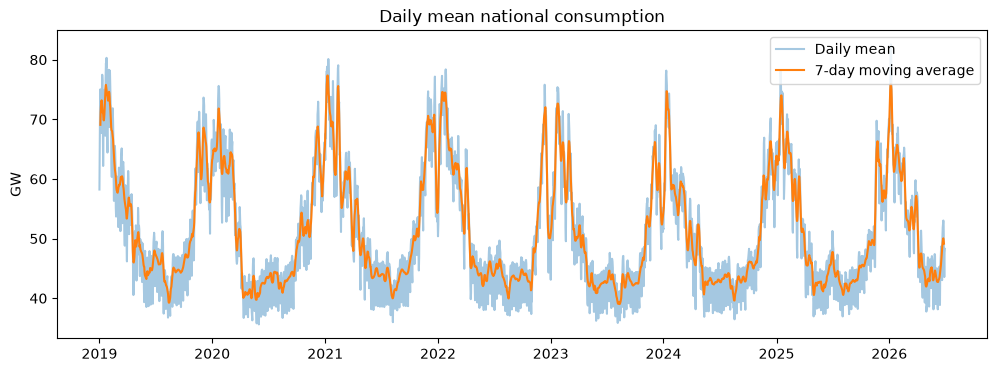

In [34]:
plt.plot(daily["date"], daily["target"], alpha=0.4, label="Daily mean")
plt.plot(daily["date"], daily["target_7d"], label="7-day moving average")
plt.title("Daily mean national consumption")
plt.ylabel("GW")
plt.legend()
plt.show()

The yearly cycle dominates, winter days are almost twice summer days. The small wiggles are the weekly cycle (see STL in Part B).

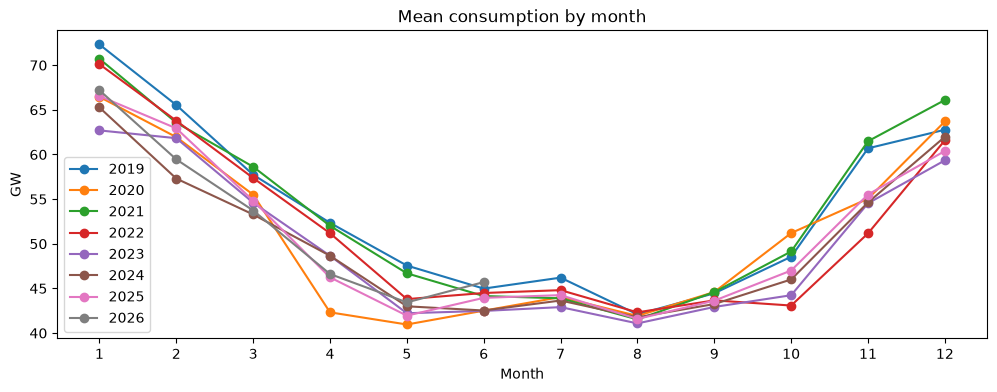

In [35]:
monthly = (
    df.with_columns(pl.col("date").dt.year().alias("year"))
    .group_by("year", "month")
    .agg((pl.col("target").mean() / 1000).alias("target"))
    .sort("year", "month")
)

for year in range(2019, 2027):
    data = monthly.filter(pl.col("year") == year)
    plt.plot(data["month"], data["target"], marker="o", label=str(year))
plt.title("Mean consumption by month")
plt.xlabel("Month")
plt.ylabel("GW")
plt.xticks(range(1, 13))
plt.legend()
plt.show()

Gaps between years are mostly in winter (temperature). Winters after 2023 are lower without being warmer, likely post-crisis sobriety. 2020 is odd too (lockdown), so training years matter.

## Daily profile by season

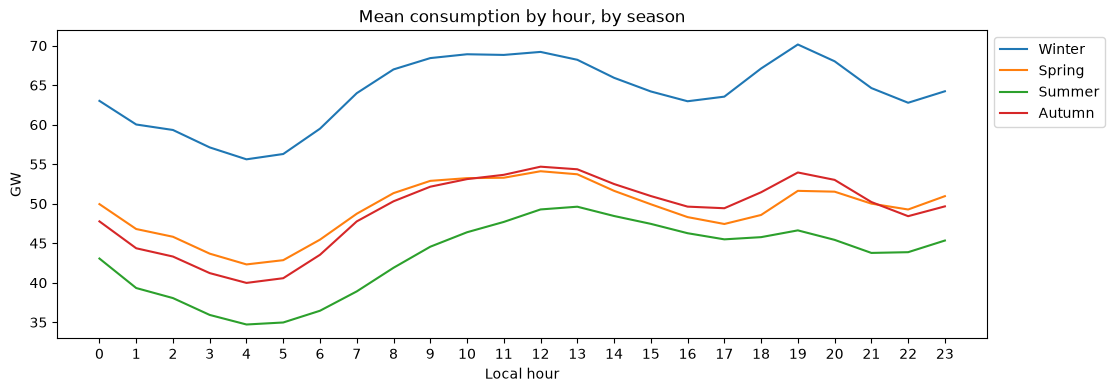

In [36]:
seasons = {
    "Winter": [12, 1, 2],
    "Spring": [3, 4, 5],
    "Summer": [6, 7, 8],
    "Autumn": [9, 10, 11],
}

for season, months in seasons.items():
    profile = (
        df.filter(pl.col("month").is_in(months))
        .group_by("hour")
        .agg((pl.col("target").mean() / 1000).alias("target"))
        .sort("hour")
    )
    plt.plot(profile["hour"], profile["target"], label=season)
plt.title("Mean consumption by hour, by season")
plt.xlabel("Local hour")
plt.ylabel("GW")
plt.xticks(range(24))
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

Same shape in every season. Winter adds a 7 pm peak (lighting on top of heating), which is the one the trading desk cares about. The small bump around 11 pm is probably water heaters on the off-peak tariff.

## Daily profile by day of the week

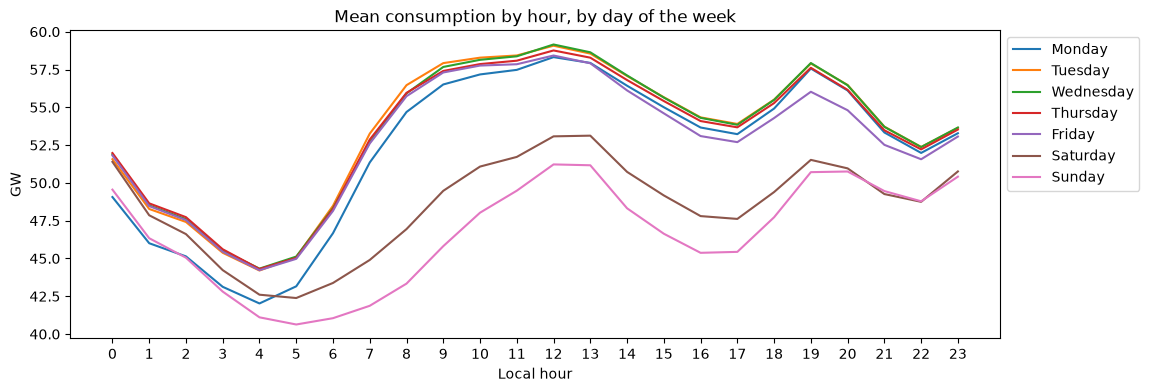

In [37]:
day_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

for weekday, name in enumerate(day_names, start=1):
    profile = (
        df.filter(pl.col("weekday") == weekday)
        .group_by("hour")
        .agg((pl.col("target").mean() / 1000).alias("target"))
        .sort("hour")
    )
    plt.plot(profile["hour"], profile["target"], label=name)
plt.title("Mean consumption by hour, by day of the week")
plt.xlabel("Local hour")
plt.ylabel("GW")
plt.xticks(range(24))
plt.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

What we see. Tuesday to Friday are almost identical. Weekends are much lower during the day (more than 10 GW less on Sunday morning), nights barely change. Hence "same day last week" as a baseline.

## Temperature sensitivity

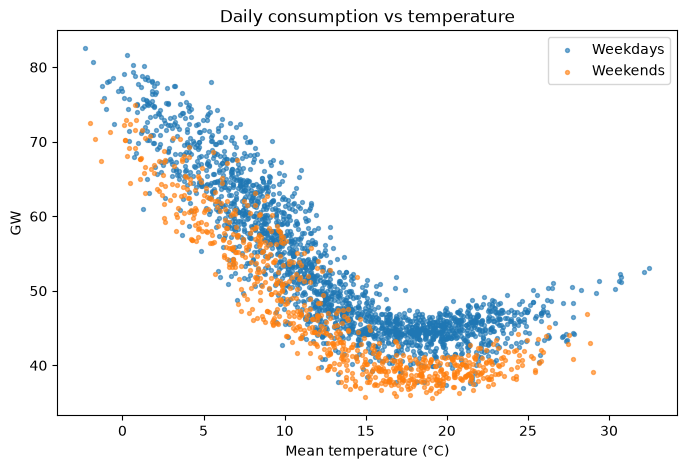

In [38]:
daily = daily.with_columns((pl.col("date").dt.weekday() <= 5).alias("is_workday"))
workdays = daily.filter(pl.col("is_workday"))
weekends = daily.filter(~pl.col("is_workday"))

plt.figure(figsize=(8, 5))
plt.scatter(workdays["temperature_c"], workdays["target"], s=8, alpha=0.6, label="Weekdays")
plt.scatter(weekends["temperature_c"], weekends["target"], s=8, alpha=0.6, label="Weekends")
plt.title("Daily consumption vs temperature")
plt.xlabel("Mean temperature (°C)")
plt.ylabel("GW")
plt.legend()
plt.show()

In [39]:
cold_days = daily.filter(pl.col("temperature_c") < 15)
slope, intercept = np.polyfit(cold_days["temperature_c"], cold_days["target"], deg=1)
print(f"Slope below 15 °C: {slope * 1000:.0f} MW per °C")

assert slope < 0, "consumption should increase when it gets colder"

Slope below 15 °C: -2117 MW per °C


Hockey stick. Below about 15 °C each degree less adds roughly 2 GW (heating), above it's flat with a small rise after 25 °C. Temperature is the key variable, but D+1's temperature is unknown at the cutoff.

# Part B: Seasonality and stationarity

## Autocorrelation

We forecast D+1 at D 12:00, so the 24 h lag isn't available for every hour. The usable lags are 48 h and 168 h.

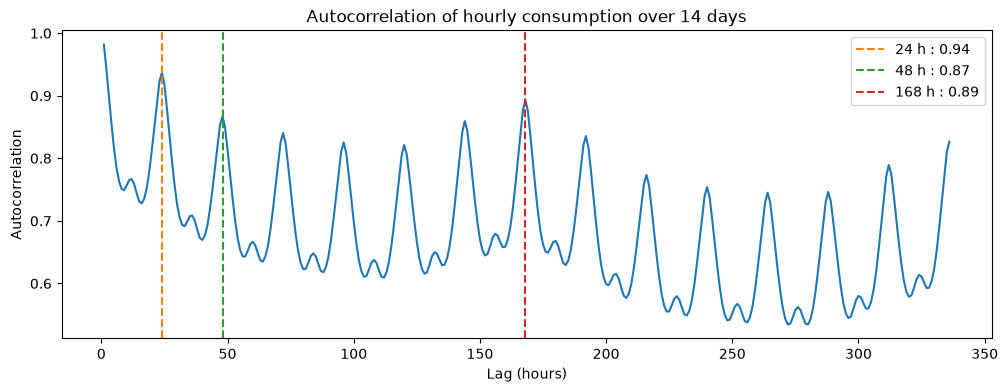

In [40]:
load = df["target"].to_numpy()
lags = np.arange(1, 14 * 24 + 1)
acf = [np.corrcoef(load[:-lag], load[lag:])[0, 1] for lag in lags]

plt.plot(lags, acf)
for lag, color in [(24, "C1"), (48, "C2"), (168, "C3")]:
    plt.axvline(lag, color=color, linestyle="--", label=f"{lag} h : {acf[lag - 1]:.2f}")
plt.title("Autocorrelation of hourly consumption over 14 days")
plt.xlabel("Lag (hours)")
plt.ylabel("Autocorrelation")
plt.legend()
plt.show()

Both usable lags are around 0.9, and 168 h is higher than 120 h or 144 h (day-of-week effect). So our first baseline is the seasonal naive (lag 7d).

## STL decomposition: weekly cycle

STL on the daily mean with period=7, so the yearly cycle goes into the trend.

In [41]:
def plot_stl(result, title):
    """Plot the trend, seasonal and residual components of an STL fit of the daily series."""
    components = {"Trend": result.trend, "Seasonal": result.seasonal, "Residual": result.resid}
    fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
    for ax, (name, values) in zip(axes, components.items()):
        ax.plot(daily["date"], values)
        ax.set_title(f"{title}: {name.lower()}")
        ax.set_ylabel("GW")
    plt.tight_layout()
    plt.show()

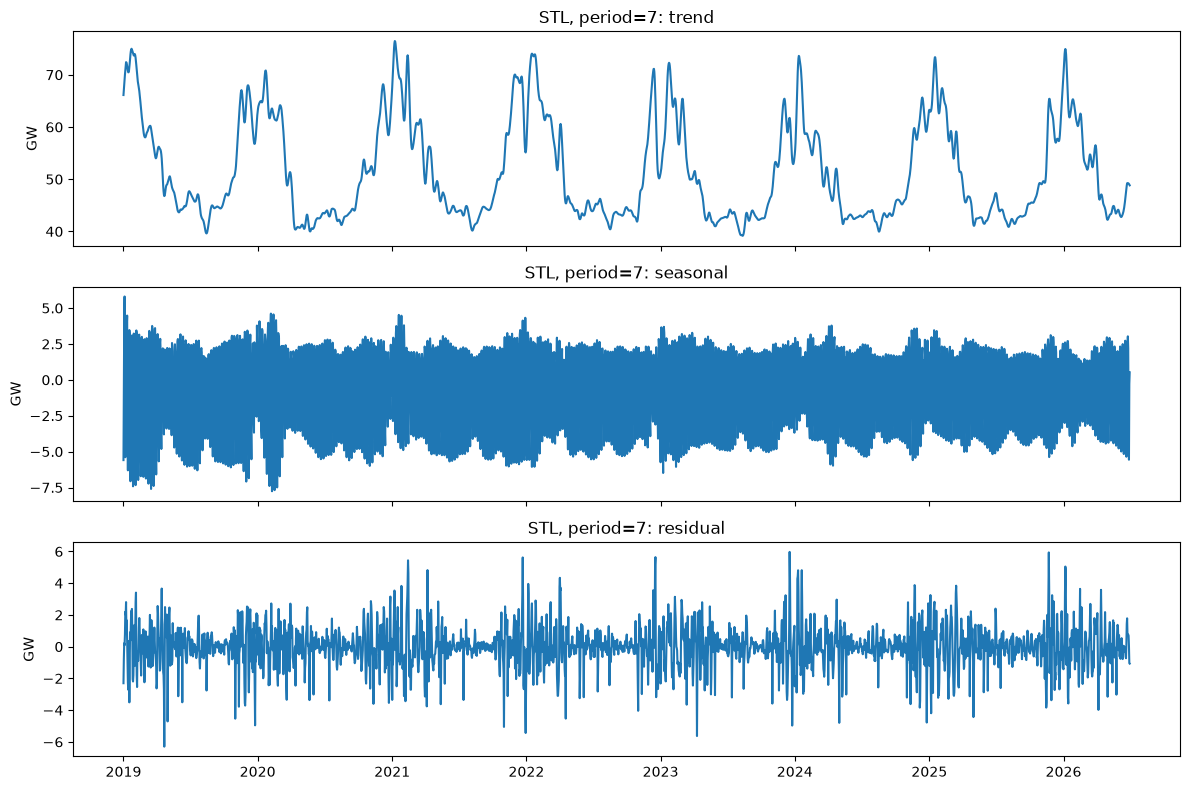

In [42]:
y = daily["target"].to_numpy()
stl_week = STL(y, period=7).fit()

assert len(stl_week.seasonal) == daily.height, "STL should return one value per day"
plot_stl(stl_week, "STL, period=7")

What we see. More than 10 GW between a weekday and a Sunday, and almost twice as wide in winter, so more multiplicative than additive (log might help). Biggest residuals are holidays and cold spells.

## STL decomposition: yearly cycle

Same series with period=365.

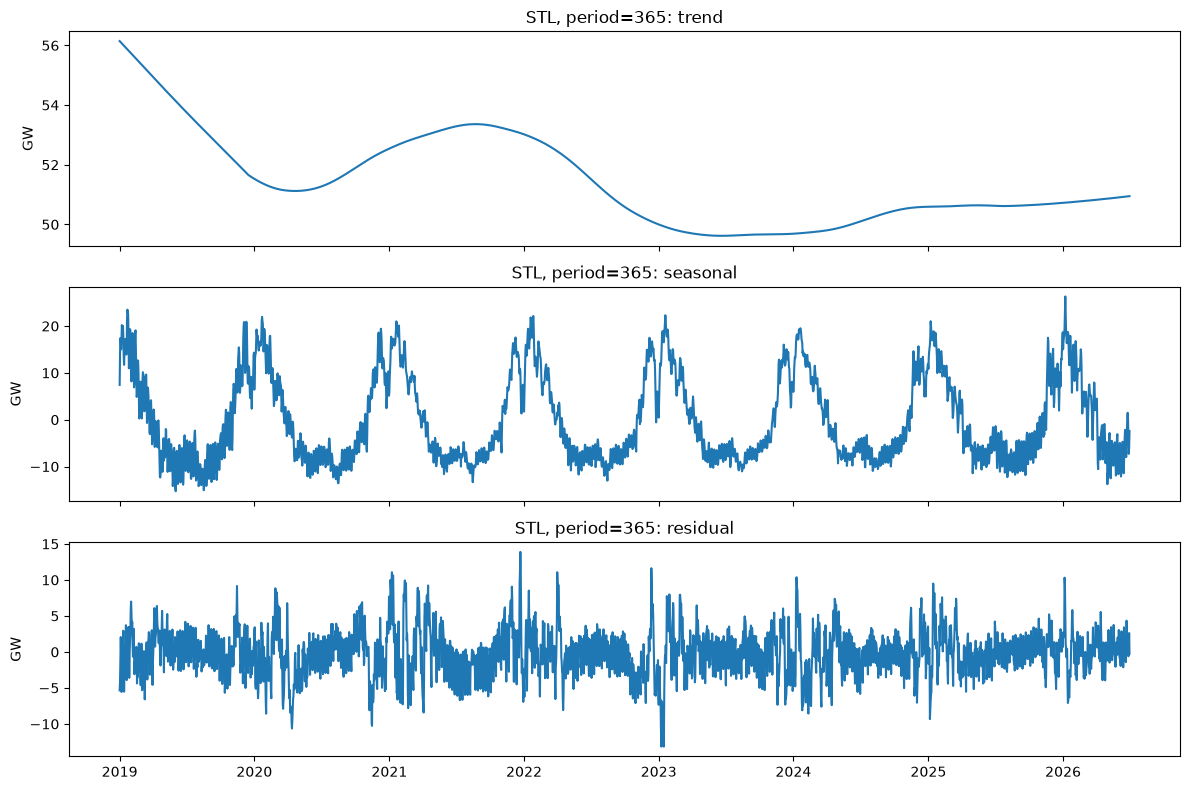

In [43]:
stl_year = STL(y, period=365).fit()
plot_stl(stl_year, "STL, period=365")

In [44]:
def strength(component, resid):
    """Strength of a component in [0, 1]: share of variance explained once the residual is added."""
    return max(0.0, 1 - np.var(resid) / np.var(component + resid))


pl.DataFrame([
    {"period": 7, "seasonal_strength": strength(stl_week.seasonal, stl_week.resid),
     "trend_strength": strength(stl_week.trend, stl_week.resid)},
    {"period": 365, "seasonal_strength": strength(stl_year.seasonal, stl_year.resid),
     "trend_strength": strength(stl_year.trend, stl_year.resid)},
]).with_columns(pl.col("seasonal_strength", "trend_strength").round(2))

period,seasonal_strength,trend_strength
i64,f64,f64
7,0.81,0.98
365,0.9,0.21


About 30 GW between summer and winter. The trend only moves a few GW, down in 2021-2023 (energy crisis) and slowly back up. The high start in 2019 is probably an STL edge effect.

## Stationarity tests: ADF and KPSS

ADF has H0 = unit root, KPSS has H0 = stationary (its p-values are capped at 0.10). We test the daily series, its weekly difference, and the series minus the yearly STL component.

In [45]:
def stationarity_tests(x):
    """ADF and KPSS p-values of a series."""
    return {"ADF_p-value": adfuller(x, result_object=True).pvalue, "KPSS_p-value": kpss(x, result_object=True).pvalue}


series = {
    "daily consumption": y,
    "weekly difference": y[7:] - y[:-7],
    "without yearly cycle": y - stl_year.seasonal,
}
assert len(series["weekly difference"]) == len(y) - 7, "a weekly difference costs 7 values"

pl.DataFrame([{"series": name, **stationarity_tests(x)} for name, x in series.items()])

series,ADF_p-value,KPSS_p-value
str,f64,f64
"""daily consumption""",0.000343,0.1
"""weekly difference""",8.6806e-17,0.1
"""without yearly cycle""",2.1274e-8,0.01


A bit surprising: both tests say the raw daily series is stationary (the yearly cycle oscillates around a fixed mean), and so is the weekly difference. Without the yearly cycle KPSS rejects, probably due to the 2022-2023 drop.

# Part C: The RTE benchmark

Error = forecast minus actual (negative means RTE underestimates). The 7 missing hours are dropped.

In [46]:
bench = df.drop_nulls("rte_forecast_j1_mw").with_columns(
    (pl.col("rte_forecast_j1_mw") - pl.col("target")).alias("error")
)
assert bench.height == df.height - 7, "only the 7 October hours should be dropped"

In [47]:
test = bench.filter(pl.col("date").is_between(date(2025, 7, 1), date(2026, 6, 30)))
assert test["date"].min() == date(2025, 7, 1) and test["date"].max() == date(2026, 6, 30), "wrong test period"

all_metrics = compute_metrics(bench, "rte_forecast_j1_mw")
test_metrics = compute_metrics(test, "rte_forecast_j1_mw")
print(f"Whole period: MAE = {all_metrics['MAE']:.0f} MW, MAPE = {all_metrics['MAPE']:.2f} %")
print(f"Last 12 months (test): MAE = {test_metrics['MAE']:.0f} MW, MAPE = {test_metrics['MAPE']:.2f} %")

Whole period: MAE = 1140 MW, MAPE = 2.24 %
Last 12 months (test): MAE = 1439 MW, MAPE = 2.86 %


What we see. RTE is good overall (around 2 % MAPE) but clearly worse on the test year, about 1.4 GW of MAE. Harder year or worse RTE? See the table by year.

In [48]:
rows = []
for year in range(2019, 2027):
    metrics = compute_metrics(bench.filter(pl.col("date").dt.year() == year), "rte_forecast_j1_mw")
    rows.append({"year": year, **metrics})

pl.DataFrame(rows).with_columns(pl.col("MAE", "RMSE", "bias").round(0), pl.col("MAPE").round(2))

year,MAE,RMSE,MAPE,bias
i64,f64,f64,f64,f64
2019,831.0,1084.0,1.54,-228.0
2020,845.0,1161.0,1.69,-115.0
2021,914.0,1202.0,1.71,-227.0
2022,1017.0,1367.0,1.98,-574.0
2023,1342.0,1678.0,2.73,-1131.0
2024,1428.0,1766.0,2.86,-1146.0
2025,1397.0,1726.0,2.82,-973.0
2026,1550.0,1889.0,2.99,-1220.0


Something changes in 2023: MAE goes up by about half and the bias jumps to around -1.1 GW. RTE didn't adapt to the lower post-crisis load, and our test period is in this regime.

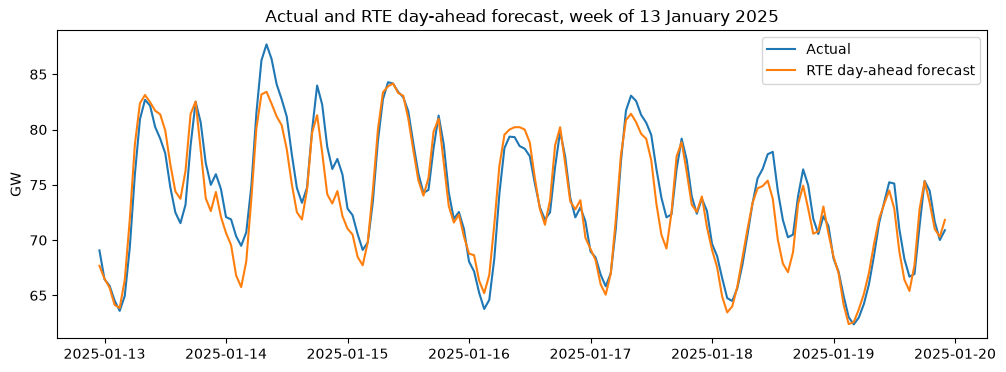

In [49]:
week = bench.filter(pl.col("date").is_between(pl.date(2025, 1, 13), pl.date(2025, 1, 19)))

plt.plot(week["datetime_local"], week["target"] / 1000, label="Actual")
plt.plot(week["datetime_local"], week["rte_forecast_j1_mw"] / 1000, label="RTE day-ahead forecast")
plt.title("Actual and RTE day-ahead forecast, week of 13 January 2025")
plt.ylabel("GW")
plt.legend()
plt.show()

The daily shape is right. Most errors are on the morning and evening peaks, often underestimated (up to about 4 GW this week).

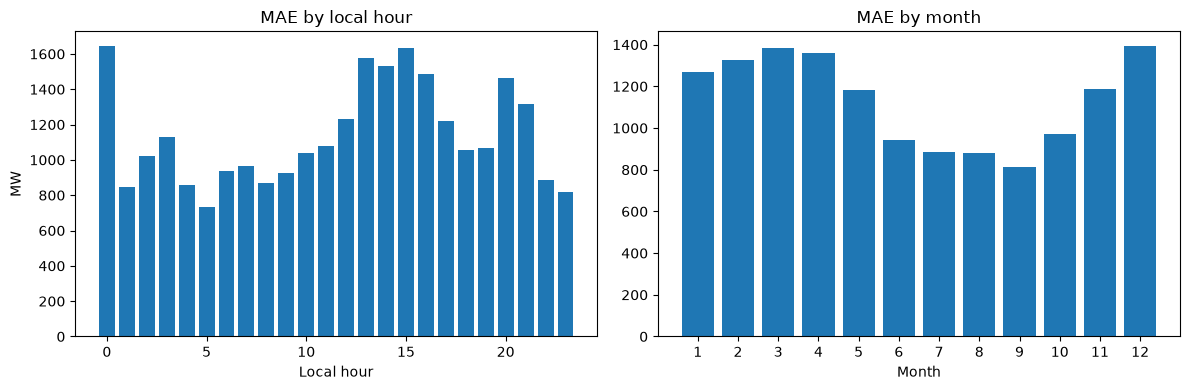

In [50]:
mae_by_hour = bench.group_by("hour").agg(pl.col("error").abs().mean().alias("mae")).sort("hour")
mae_by_month = bench.group_by("month").agg(pl.col("error").abs().mean().alias("mae")).sort("month")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.bar(mae_by_hour["hour"], mae_by_hour["mae"])
ax1.set_title("MAE by local hour")
ax1.set_xlabel("Local hour")
ax1.set_ylabel("MW")
ax2.bar(mae_by_month["month"], mae_by_month["mae"])
ax2.set_title("MAE by month")
ax2.set_xlabel("Month")
ax2.set_xticks(range(1, 13))
plt.tight_layout()
plt.show()

Error is lower at night and in the morning, higher around midnight and early afternoon, and bigger in winter. Midnight is probably the water heaters again.

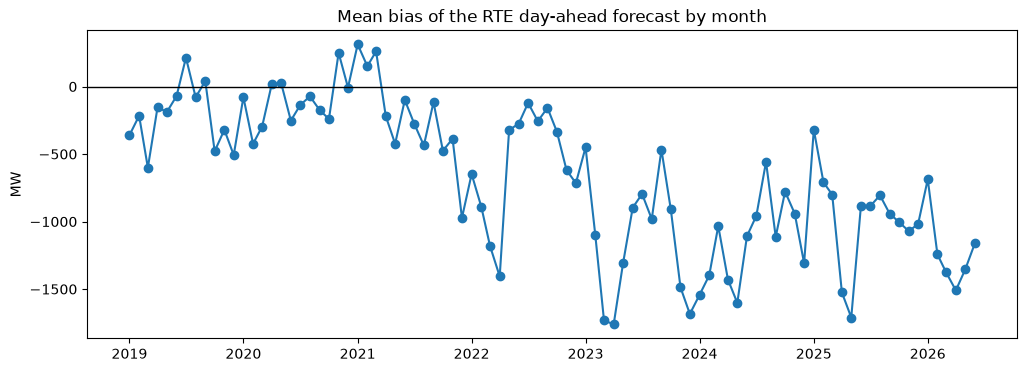

In [51]:
bias_by_month = (
    bench.group_by(pl.col("date").dt.truncate("1mo").alias("month_start"))
    .agg(pl.col("error").mean().alias("bias"))
    .sort("month_start")
)

plt.plot(bias_by_month["month_start"], bias_by_month["bias"], marker="o")
plt.axhline(0, color="black", linewidth=1)
plt.title("Mean bias of the RTE day-ahead forecast by month")
plt.ylabel("MW")
plt.show()

What we see. Small two-sided bias before 2022, negative every single month since 2023. Good news for us, a systematic error can be corrected.

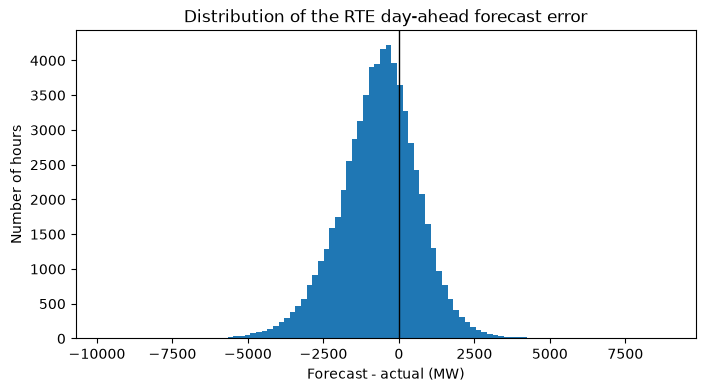

In [52]:
plt.figure(figsize=(8, 4))
plt.hist(bench["error"], bins=100)
plt.axvline(0, color="black", linewidth=1)
plt.title("Distribution of the RTE day-ahead forecast error")
plt.xlabel("Forecast - actual (MW)")
plt.ylabel("Number of hours")
plt.show()

Roughly normal but shifted left, about 70 % of hours are underestimated. Errors above 4 GW are rare, so the MAE is mostly bias plus normal noise.

# Conclusion

- Three seasonalities (daily, weekly, yearly) and a strong heating effect below 15 °C. Calendar and temperature will be the main inputs, but D+1 temperature is unknown at the cutoff.
- Only the 48 h and 168 h lags are usable. Lag 7d works best, so it's our first baseline.
- No unit root, so no first difference, but the 2022-2023 drop makes the choice of training years important.
- RTE is hard to beat but underestimates by about 1 GW since 2023. Its raw forecast is the benchmark.